In [1]:
#Q 2
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


In [2]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

mnist_tf = transforms.Compose([transforms.ToTensor(),
                               transforms.Normalize((0.1307,), (0.3081,))])
train_set = torchvision.datasets.MNIST('./data1', train=True, download=True,
                                       transform=mnist_tf)
test_set = torchvision.datasets.MNIST('./data1', train=False, download=True,
                                      transform=mnist_tf)
trainloader = torch.utils.data.DataLoader(train_set, batch_size=64, shuffle=True)
testloader = torch.utils.data.DataLoader(test_set, batch_size=1000, shuffle=False)



Using device: cpu


100%|██████████| 9.91M/9.91M [00:05<00:00, 1.85MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 96.9kB/s]
100%|██████████| 1.65M/1.65M [00:02<00:00, 780kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.21MB/s]


In [3]:

class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, 5, padding=2), nn.Tanh(), nn.AvgPool2d(2),   # 28 -> 14
            nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2))             # 10 -> 5
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(),
            nn.Linear(84, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1),
                nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2))

        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))  # 28->14->7->3
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.3),
            nn.Linear(128 * 3 * 3, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * y.size(0)
            pred = out.argmax(1)
            correct += (pred == y).sum().item()
            total += y.size(0)
            all_preds.append(pred.cpu())
            all_labels.append(y.cpu())
    return (total_loss / total, 100 * correct / total,
            torch.cat(all_preds), torch.cat(all_labels))


def train_model(model, epochs=10, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

    for ep in range(epochs):
        model.train()
        for x, y in trainloader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()

        tr_loss, tr_acc, _, _ = evaluate(model, trainloader, criterion)
        te_loss, te_acc, _, _ = evaluate(model, testloader, criterion)
        hist["train_loss"].append(tr_loss)
        hist["train_acc"].append(tr_acc)
        hist["test_loss"].append(te_loss)
        hist["test_acc"].append(te_acc)
        print(f"Epoch {ep+1}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.2f}% "
              f"| test loss {te_loss:.4f} acc {te_acc:.2f}%")
    return hist



Epoch 1/10 | train loss 0.0984 acc 97.01% | test loss 0.0997 acc 96.83%
Epoch 2/10 | train loss 0.0581 acc 98.14% | test loss 0.0638 acc 97.98%
Epoch 3/10 | train loss 0.0387 acc 98.80% | test loss 0.0538 acc 98.32%
Epoch 4/10 | train loss 0.0291 acc 99.11% | test loss 0.0435 acc 98.50%
Epoch 5/10 | train loss 0.0309 acc 99.01% | test loss 0.0451 acc 98.59%
Epoch 6/10 | train loss 0.0261 acc 99.21% | test loss 0.0447 acc 98.49%
Epoch 7/10 | train loss 0.0171 acc 99.46% | test loss 0.0396 acc 98.83%
Epoch 8/10 | train loss 0.0158 acc 99.53% | test loss 0.0422 acc 98.63%
Epoch 9/10 | train loss 0.0150 acc 99.54% | test loss 0.0448 acc 98.71%
Epoch 10/10 | train loss 0.0103 acc 99.68% | test loss 0.0395 acc 98.78%


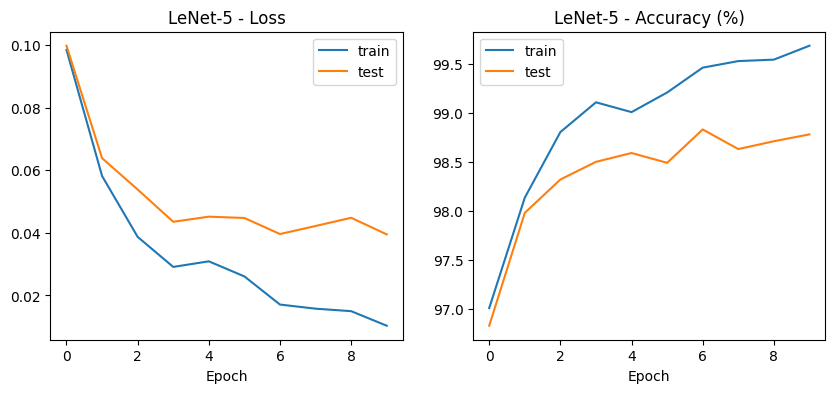

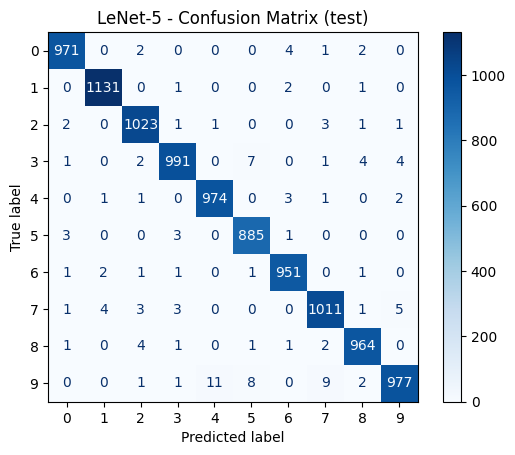

In [4]:

def plot_history(hist, name):
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].plot(hist["train_loss"], label="train")
    ax[0].plot(hist["test_loss"], label="test")
    ax[0].set_title(f"{name} - Loss")
    ax[0].set_xlabel("Epoch")
    ax[0].legend()
    ax[1].plot(hist["train_acc"], label="train")
    ax[1].plot(hist["test_acc"], label="test")
    ax[1].set_title(f"{name} - Accuracy (%)")
    ax[1].set_xlabel("Epoch")
    ax[1].legend()
    plt.show()


def show_confusion(model, name):
    _, _, preds, labels = evaluate(model, testloader, nn.CrossEntropyLoss())
    cm = confusion_matrix(labels, preds)
    ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(cmap="Blues")
    plt.title(f"{name} - Confusion Matrix (test)")
    plt.show()


lenet = LeNet5()
lenet_hist = train_model(lenet, epochs=10)
plot_history(lenet_hist, "LeNet-5")
show_confusion(lenet, "LeNet-5")


Epoch 1/10 | train loss 0.0327 acc 99.02% | test loss 0.0374 acc 98.73%
Epoch 2/10 | train loss 0.0254 acc 99.17% | test loss 0.0281 acc 99.16%
Epoch 3/10 | train loss 0.0315 acc 99.00% | test loss 0.0404 acc 98.69%
Epoch 4/10 | train loss 0.0173 acc 99.48% | test loss 0.0295 acc 99.06%
Epoch 5/10 | train loss 0.0136 acc 99.59% | test loss 0.0250 acc 99.20%
Epoch 6/10 | train loss 0.0119 acc 99.61% | test loss 0.0282 acc 99.16%
Epoch 7/10 | train loss 0.0090 acc 99.70% | test loss 0.0250 acc 99.25%
Epoch 8/10 | train loss 0.0057 acc 99.82% | test loss 0.0221 acc 99.33%
Epoch 9/10 | train loss 0.0051 acc 99.86% | test loss 0.0267 acc 99.24%
Epoch 10/10 | train loss 0.0037 acc 99.90% | test loss 0.0245 acc 99.33%


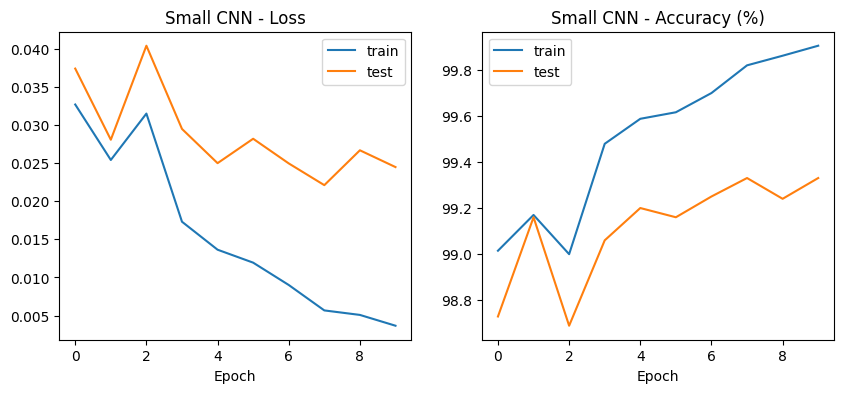

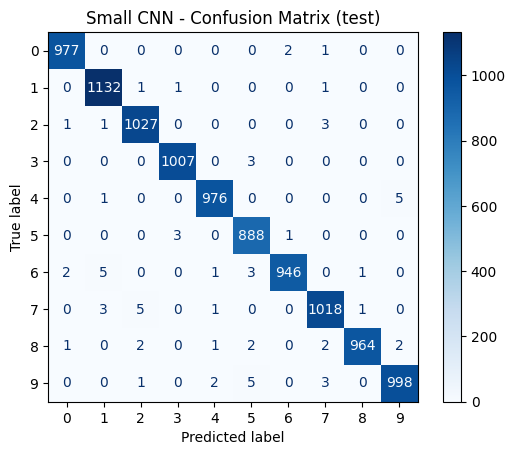

LeNet-5   : train 99.68%, test 98.78%
Small CNN : train 99.90%, test 99.33%


In [5]:

cnn = SmallCNN()
cnn_hist = train_model(cnn, epochs=10)
plot_history(cnn_hist, "Small CNN")
show_confusion(cnn, "Small CNN")

print(f"LeNet-5   : train {lenet_hist['train_acc'][-1]:.2f}%, test {lenet_hist['test_acc'][-1]:.2f}%")
print(f"Small CNN : train {cnn_hist['train_acc'][-1]:.2f}%, test {cnn_hist['test_acc'][-1]:.2f}%")